[See this](https://www.nltk.org/book/ch02.html)

In [1]:
import nltk
# from nltk.corpus import brown


In [2]:
# nltk.download()

In [3]:
nltk.download('words')

[nltk_data] Downloading package words to /root/nltk_data...
[nltk_data]   Unzipping corpora/words.zip.


True

In [4]:
# nltk.download('brown')

In [5]:
from nltk.corpus import words

In [6]:
# words?

In [7]:
allwords = set(words.words())

In [8]:
import pandas as pd, numpy as np, os,glob
from matplotlib import pyplot as plt

# Remove all names, the first letter is capitalized

In [9]:
import string


# [cardinal to ordinal](https://stackoverflow.com/questions/9647202/ordinal-numbers-replacement)
```
['1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th',
 '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th',
 '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th',
 '29th', '30th', '31st']
 ```

In [10]:
cardinals = ['1st', '2nd', '3rd', '4th', '5th', '6th', '7th', '8th', '9th', '10th',
 '11th', '12th', '13th', '14th', '15th', '16th', '17th', '18th', '19th',
 '20th', '21st', '22nd', '23rd', '24th', '25th', '26th', '27th', '28th',
 '29th', '30th', '31st']
ordinal = lambda n: "%d%s" % (n,"tsnrhtdd"[(n//10%10!=1)*(n%10<4)*n%10::4])
# cardinals = {n:ordinal(n) for n in range(1,24)}
blank_cardinals = {card:None for card in cardinals}
cardinals
# blank_cardinals

['1st',
 '2nd',
 '3rd',
 '4th',
 '5th',
 '6th',
 '7th',
 '8th',
 '9th',
 '10th',
 '11th',
 '12th',
 '13th',
 '14th',
 '15th',
 '16th',
 '17th',
 '18th',
 '19th',
 '20th',
 '21st',
 '22nd',
 '23rd',
 '24th',
 '25th',
 '26th',
 '27th',
 '28th',
 '29th',
 '30th',
 '31st']

In [11]:
results = dict()
bad_characters = {'$','-',',','1','2','3','4','5','6','7','8','9','0','\''}
bad_characters = set(string.ascii_uppercase)
alphabet_list = set(string.ascii_lowercase)
for i,w in enumerate(allwords):
    skip = False
    for bc in bad_characters:
        if bc in w[0]:
            skip = True
            continue
    if not skip:
        row = {'word':w
            ,'len':len(w)
            #,'-':'-' in w
            #,'$': '$' in w
            } 
        word_as_list = list(w)
        # blank_cardinals = {card:None for card in cardinals}
        n = len(w)
        for j,card in enumerate(cardinals):
            if j <= n-1: ##n-1 cuz of zero based indexing
                row[card] = word_as_list[j]
            else:
                row[card] = None
        # row['first letter'] = word_as_list[0]
        # row['second letter'] = word_as_list[1]
        # row['third letter'] = word_as_list[2]
        # row['fourth letter'] = word_as_list[3]
        # row['fifth letter'] = word_as_list[4]
        # row['sixth letter'] = word_as_list[5]

        ## create encoding 
        for letter in string.ascii_lowercase:
            if letter in w:
                row[letter] = True
            else:
                row[letter] = False
        results[i] = row

# print(len(results))
m = pd.DataFrame(results).T ## m for main

vowels = ['a','e','i','o','u','y']
vowels = {'a','e','i','o','u','y'}
consonants = list(set(alphabet_list) - vowels)
m['unique_number_of_vowels'] = m[vowels].sum(axis=1) #only counts unique vowels
m['unique_number_of_consonants'] = m[consonants].sum(axis=1)
m['unique_number_of_letters'] = m['unique_number_of_vowels'] + m['unique_number_of_consonants']

vowel_nums = []
## how to improve algorithmic complexity - make vowels a set
for word in m['word']:
    vowel_count_for_word = 0
    for letter in word:
        if letter in vowels:
            vowel_count_for_word += 1
    vowel_nums.append(vowel_count_for_word)
m['number_of_vowels'] = vowel_nums #only counts unique vowels
m['number_of_consonants'] = 5 - m['number_of_vowels']
# m.drop(index=m.loc[],inplace=True)

# Need to sort the order of the alphabet

In [12]:
m

,word,len,1st,2nd,3rd,4th,5th,6th,7th,8th,...,v,w,x,y,z,unique_number_of_vowels,unique_number_of_consonants,unique_number_of_letters,number_of_vowels,number_of_consonants
0,weatherhead,11,w,e,a,t,h,e,r,h,...,False,True,False,False,False,2.0,5.0,7.0,5,0
1,coracobrachialis,16,c,o,r,a,c,o,b,r,...,False,False,False,False,False,3.0,6.0,9.0,7,-2
2,defendant,9,d,e,f,e,n,d,a,n,...,False,False,False,False,False,2.0,4.0,6.0,3,2
3,streptothricosis,16,s,t,r,e,p,t,o,t,...,False,False,False,False,False,3.0,6.0,9.0,5,0
4,constate,8,c,o,n,s,t,a,t,e,...,False,False,False,False,False,3.0,4.0,7.0,3,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
235886,uncirculated,12,u,n,c,i,r,c,u,l,...,False,False,False,False,False,4.0,6.0,10.0,5,0
235887,undersheriffry,14,u,n,d,e,r,s,h,e,...,False,False,False,True,False,4.0,6.0,10.0,5,0
235888,repped,6,r,e,p,p,e,d,None,None,...,False,False,False,False,False,1.0,3.0,4.0,2,3
235889,cutaneous,9,c,u,t,a,n,e,o,u,...,False,False,False,False,False,4.0,4.0,8.0,5,0


In [13]:
len(allwords) == m.shape[0],len(allwords),m.shape[0]

(False, 235892, 210693)

In [14]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [22]:
letter_length = 2
# raise
for letter_length in range(2,5):
    card_cols_to_remove = [ordinal(n) for n in range(letter_length + 1,32)]
    ## set difference could work but I want to maintain the order
    keep = list(m.columns.values) 
    keep.remove('len')
    for ind_col_to_remove in card_cols_to_remove:
        try:
            keep.remove(ind_col_to_remove)
        except:
            # print(ind_col_to_remove,'not in keep')
            pass
    p = 'drive/MyDrive/<your-folder>/WORDLE/NLTK Word Copora Parsed/'
    m.loc[m['len'] == letter_length,keep].to_csv(p + f'{letter_length} letter words parsed - NLTK Words Corpora - v0.csv',index=False)

In [ ]:
# m.len.hist()
# plt.title('Word Len Distribution')
# plt.show()

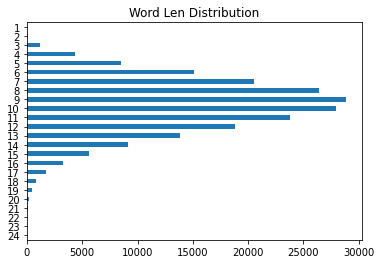

In [ ]:
m.len.value_counts().sort_index(ascending=False).plot(kind='barh',title='Word Len Distribution')
plt.show()

# Are these actual words - looks like there are names in here

In [ ]:
'V' in "Veronica"

True

# Parse the words into a spreadsheet and export into groups - by letter size
- <font color = 'red'> Compare the madalynrose dataset I currently have to this dataset </font>

In [ ]:
m.loc[m.len == 5].sample(15)

,word,len
190843,thana,5
120973,lurid,5
53833,crude,5
153078,cauma,5
191505,tibet,5
166122,stosh,5
78150,nudge,5
9721,kraut,5
195399,glare,5
58005,shoal,5
